In [1]:
!pip install tensorflow tensorflow.keras
!pip install numpy
!pip install scipy
!pip install pandas
!pip install matplotlib
!pip install scikit-learn


Coercion summary (new NaNs introduced by coercion):
  shallow_depth_s: +0 NaNs
  Deep_depth_s: +0 NaNs
  Deep_depth_t: +0 NaNs
  chlorophyll_depth: +0 NaNs
Examples of original values coerced to NaN (up to 5 examples per column):
  shallow_depth_s: []
  Deep_depth_s: []
  Deep_depth_t: []
  chlorophyll_depth: []
Dropped 2 rows with NaNs in required columns (remaining 600 rows).
Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):
     shallow_depth_s  Deep_depth_s  Deep_depth_t  chlorophyll_depth  \
170            0.100           NaN         3.463              0.724   
601            9.431        13.026           NaN              4.648   

       drop_reasons  
170  [Deep_depth_s]  
601  [Deep_depth_t]  
Saved cleaned data to 'data_cleaned.csv'
Original DataFrame shape: (602, 10)
DataFrame shape after coercion+outlier removal: (516, 10)


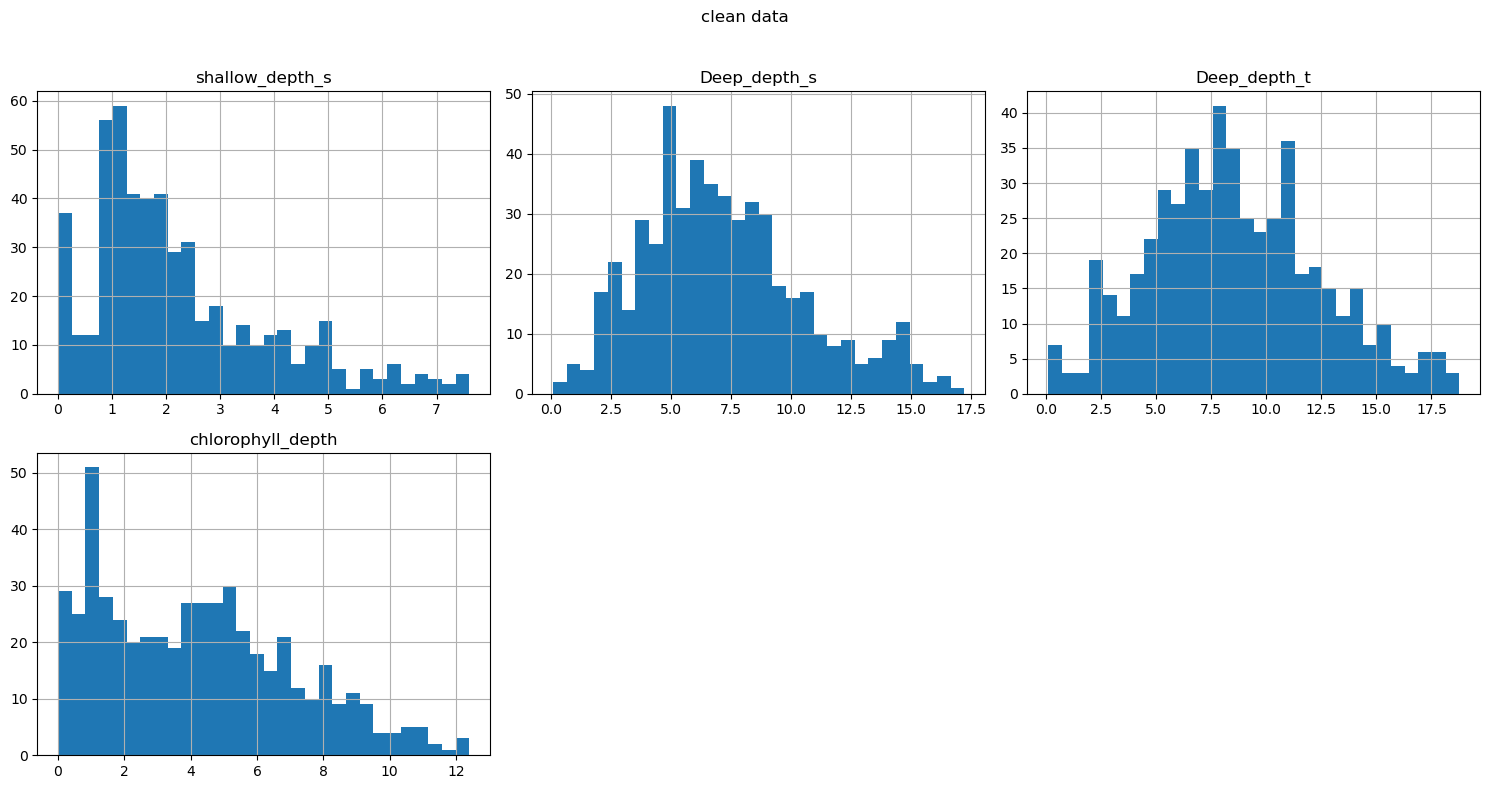

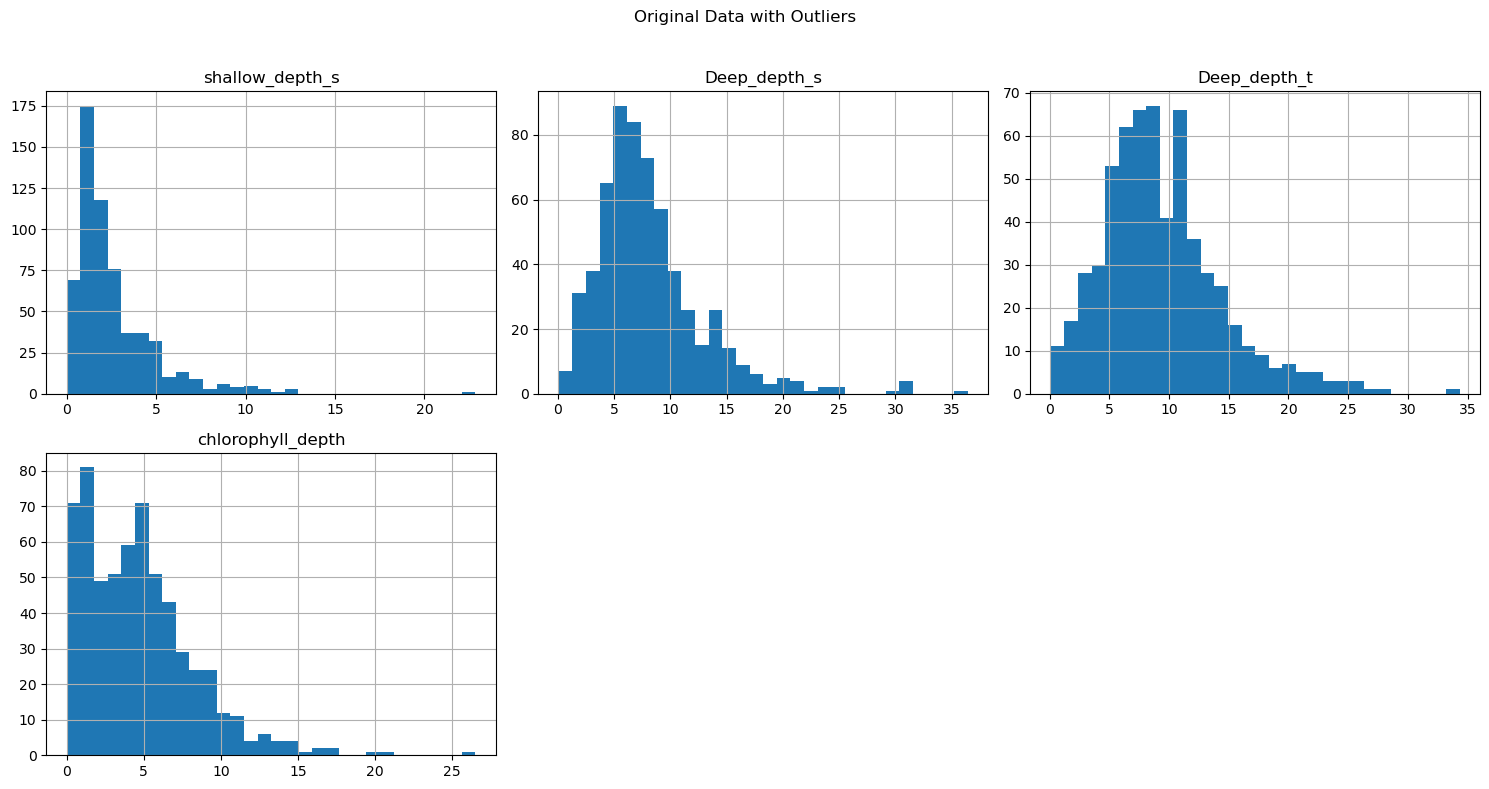

In [35]:

# 2. Load and Prepare Your Data
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Load data
data = pd.read_csv('Raw data chlorocline.csv', encoding='latin-1') # Try 'latin-1' encoding

# Feature and target columns (ensure these match your CSV headers)
feature_cols = ['shallow_depth_s', 'Deep_depth_s', 'Deep_depth_t']
target_col = 'chlorophyll_depth'


def remove_outliers(df):
    """
    Removes rows containing outliers in the specified columns using the Z-score method.
    """
    df_cleaned = df.copy()
    cols_to_check = feature_cols + [target_col]
    present_cols = [c for c in cols_to_check if c in df_cleaned.columns]
    missing_cols = [c for c in cols_to_check if c not in df_cleaned.columns]
    if missing_cols:
        print(f"Warning: Column(s) not found in the DataFrame and will be skipped: {missing_cols}")

    # Ensure we don't try to z-score constant or empty columns
    for col in present_cols:
        # coerce object columns to numeric where possible
        if df_cleaned[col].dtype == object:
            df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')
        if df_cleaned[col].dropna().nunique() <= 1:
            continue
        # compute zscore safely
        try:
            z = stats.zscore(df_cleaned[col].astype(float))
        except Exception:
            continue
        outlier_mask = np.abs(z) > 2.15  # adjust threshold if desired
        df_cleaned = df_cleaned[~outlier_mask]

    return df_cleaned


def coerce_and_clean_numeric(df, cols, target_col):
    """Coerce listed columns to numeric, replace infs, drop rows with NaNs, and provide diagnostics.

    Returns the cleaned DataFrame (rows kept). Also saves dropped rows to 'dropped_rows_inspection.csv'.
    """
    df2 = df.copy()
    converted = {}
    coercion_examples = {}

    for c in cols + [target_col]:
        if c in df2.columns:
            before_na = df2[c].isna().sum()
            # attempt coercion and capture examples of values that fail
            coerced = pd.to_numeric(df2[c], errors='coerce')
            coerced_mask = df2[c].notna() & coerced.isna()
            coercion_examples[c] = df2.loc[coerced_mask, c].head(5).tolist()
            df2[c] = coerced
            after_na = df2[c].isna().sum()
            converted[c] = after_na - before_na

    # Replace inf values with NaN
    df2 = df2.replace([np.inf, -np.inf], np.nan)

    print("Coercion summary (new NaNs introduced by coercion):")
    for k, v in converted.items():
        print(f"  {k}: +{v} NaNs")

    print("Examples of original values coerced to NaN (up to 5 examples per column):")
    for k, v in coercion_examples.items():
        print(f"  {k}: {v}")

    present_cols = [c for c in cols + [target_col] if c in df2.columns]
    before = df2.shape[0]

    # identify rows that will be dropped and keep a copy for diagnostics
    dropped_rows = df2[df2[present_cols].isnull().any(axis=1)].copy() if present_cols else df2.iloc[0:0].copy()
    df2_kept = df2.dropna(subset=present_cols) if present_cols else df2.copy()
    after = df2_kept.shape[0]

    print(f"Dropped {before - after} rows with NaNs in required columns (remaining {after} rows).")

    if not dropped_rows.empty:
        # summarize drop reasons per-row
        def reasons(row):
            return [col for col in present_cols if pd.isna(row[col])]
        dropped_rows['drop_reasons'] = dropped_rows.apply(reasons, axis=1)
        # save dropped rows for inspection
        try:
            dropped_rows.to_csv('dropped_rows_inspection.csv', index=False)
            print("Saved dropped rows to 'dropped_rows_inspection.csv' (first 5 rows):")
        except Exception as e:
            print("Failed to save dropped_rows_inspection.csv:", e)
        display_cols = [c for c in present_cols if c in dropped_rows.columns]
        print(dropped_rows.head()[display_cols + ['drop_reasons']])

    return df2_kept


# Apply cleaning and outlier removal
if 'data' in locals():
    data_numeric = coerce_and_clean_numeric(data, feature_cols, target_col)
    data_cleaned = remove_outliers(data_numeric)
    # Save cleaned data for inspection
    try:
        data_cleaned.to_csv('data_cleaned.csv', index=False)
        print("Saved cleaned data to 'data_cleaned.csv'")
    except Exception as e:
        print("Failed to save data_cleaned.csv:", e)

    print("Original DataFrame shape:", data.shape)
    print("DataFrame shape after coercion+outlier removal:", data_cleaned.shape)
else:
    print("Please load your DataFrame into a variable named 'data' before running this code.")


def plot_histograms(data, feature_cols, target_col, title):
    """
    Plots histograms for the specified feature columns and target column.

    Args:
        data (pd.DataFrame): The input DataFrame.
        feature_cols (list): List of feature column names.
        target_col (str): The target column name.
    """
    columns_to_plot = [c for c in feature_cols + [target_col] if c in data.columns]
    if not columns_to_plot:
        print("No columns available to plot.")
        return
    data[columns_to_plot].hist(bins=30, figsize=(15, 8), layout=(2, 3))
    plt.suptitle(title)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# If data_cleaned exists, plot histograms
if 'data_cleaned' in locals():
    plot_histograms(data_cleaned, feature_cols, target_col, 'clean data')
if 'data' in locals():
    plot_histograms(data, feature_cols, target_col, "Original Data with Outliers")


Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 13.2355 - val_loss: 9.5281
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4559 - val_loss: 9.8400
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1571 - val_loss: 10.1844
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1794 - val_loss: 9.9818
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2264 - val_loss: 9.8620
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0776 - val_loss: 9.6353
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2427 - val_loss: 9.7345
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7621 - val_loss: 9.9275
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7351 - val_loss: 9.8814
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8774 - val_loss: 9.7906
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.3669 - val_loss: 9.4608
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9966 - val

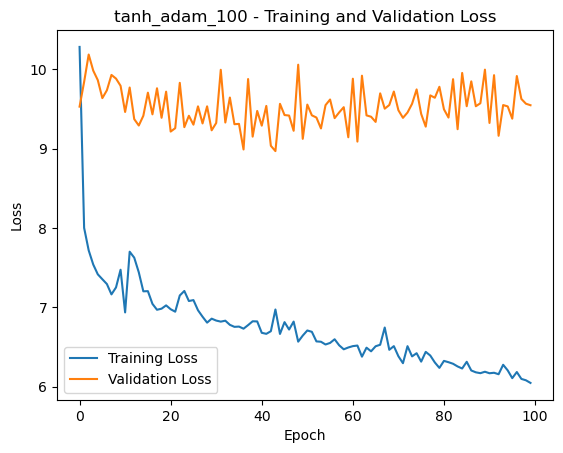

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 13.6967 - val_loss: 9.4241
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1463 - val_loss: 9.7875
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2980 - val_loss: 9.9205
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0861 - val_loss: 10.0224
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7917 - val_loss: 10.1084
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3063 - val_loss: 9.9807
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2223 - val_loss: 9.9507
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7823 - val_loss: 9.8162
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.2752 - val_loss: 9.7494
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9608 - val_loss: 9.7731
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.7572 - val_loss: 9.2050
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.5917 - va

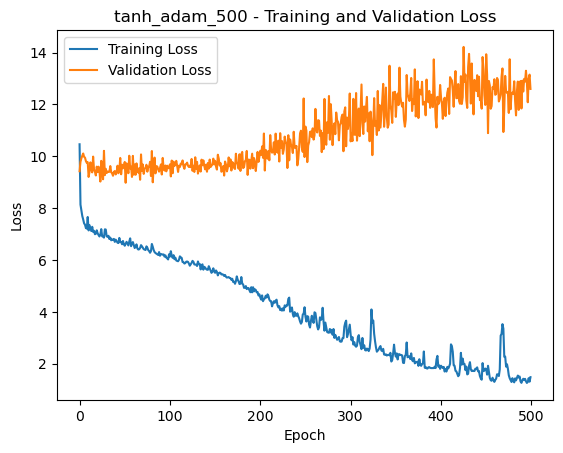

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 11.9834 - val_loss: 9.7551
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.7715 - val_loss: 9.6958
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.3475 - val_loss: 10.6278
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.5252 - val_loss: 9.8403
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2965 - val_loss: 13.8264
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.7123 - val_loss: 10.0321
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.4380 - val_loss: 10.5255
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.7403 - val_loss: 9.9688
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.7507 - val_loss: 10.9346
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.7529 - val_loss: 10.5507
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5651 - val_loss: 11.0070
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.9256

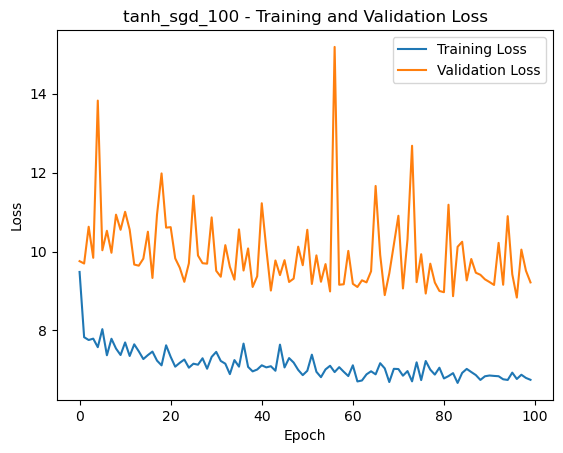

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 16.1515 - val_loss: 9.4852
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0319 - val_loss: 9.8733
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.1307 - val_loss: 9.5497
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.0040 - val_loss: 12.0484
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 10.2319 - val_loss: 9.8602
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.1928 - val_loss: 9.6062
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5631 - val_loss: 10.9474
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.3685 - val_loss: 9.9351
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0791 - val_loss: 9.7291
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.1095 - val_loss: 9.5309
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.3884 - val_loss: 9.8313
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.4391 - v

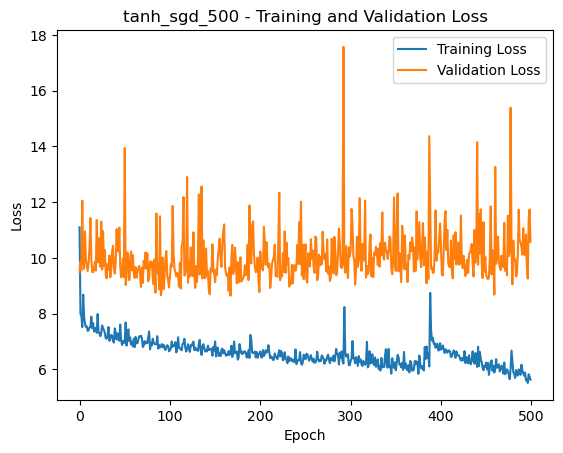

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 12.0979 - val_loss: 9.3387
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6075 - val_loss: 9.7398
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3570 - val_loss: 9.8085
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.7439 - val_loss: 9.5716
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5872 - val_loss: 10.1741
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8094 - val_loss: 9.4904
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0773 - val_loss: 10.7639
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3372 - val_loss: 10.7116
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.9818 - val_loss: 9.7105
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.6337 - val_loss: 9.3300
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.4052 - val_loss: 9.6831
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5614 - v

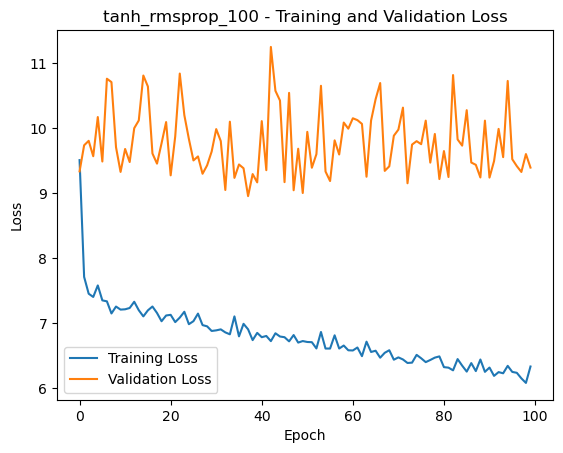

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 11.4048 - val_loss: 9.4161
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7235 - val_loss: 9.5569
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2725 - val_loss: 9.5714
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5961 - val_loss: 9.5755
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8071 - val_loss: 9.7244
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.0410 - val_loss: 10.9237
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2075 - val_loss: 9.7940
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.2950 - val_loss: 9.9874
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7565 - val_loss: 9.4456
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8473 - val_loss: 10.0461
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9790 - val_loss: 9.7811
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3608 - va

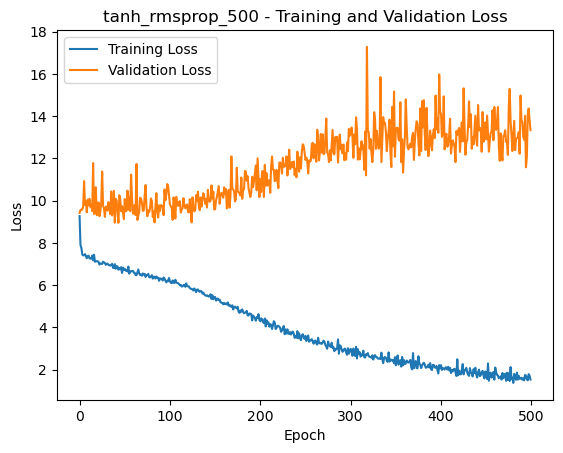

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 25.3180 - val_loss: 23.0120
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 17.1336 - val_loss: 17.5220
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 15.7813 - val_loss: 14.3424
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 11.4629 - val_loss: 12.6801
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.8575 - val_loss: 11.6343
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5660 - val_loss: 11.0608
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.0981 - val_loss: 10.6819
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1677 - val_loss: 10.4134
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1628 - val_loss: 10.2248
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5371 - val_loss: 10.0512
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1394 - val_loss: 9.9528
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 

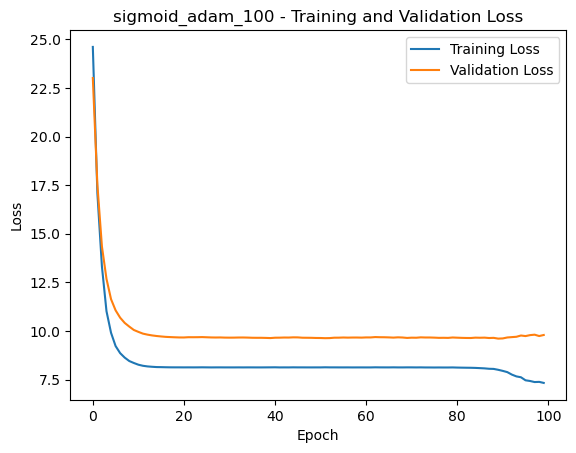

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 28.6243 - val_loss: 24.4854
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 19.7923 - val_loss: 18.1699
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 14.9333 - val_loss: 14.9461
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.8928 - val_loss: 13.1566
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.7291 - val_loss: 12.0556
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.6084 - val_loss: 11.3065
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.0799 - val_loss: 10.8294
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.5335 - val_loss: 10.5024
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4057 - val_loss: 10.2799
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7936 - val_loss: 10.0976
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.8838 - val_loss: 9.9709
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss:

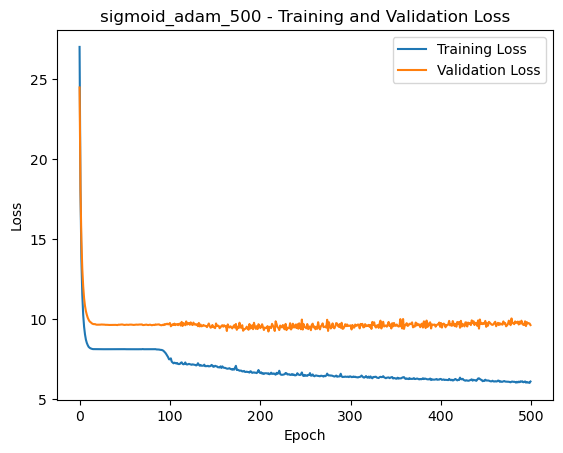

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 11.1097 - val_loss: 9.7407
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1748 - val_loss: 9.5781
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9384 - val_loss: 9.5794
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.7081 - val_loss: 9.6645
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.1274 - val_loss: 9.6806
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9515 - val_loss: 9.9845
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.3044 - val_loss: 9.9004
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2253 - val_loss: 9.6132
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0578 - val_loss: 9.7575
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.1593 - val_loss: 9.6281
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.3755 - val_loss: 9.5999
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1012 - val_

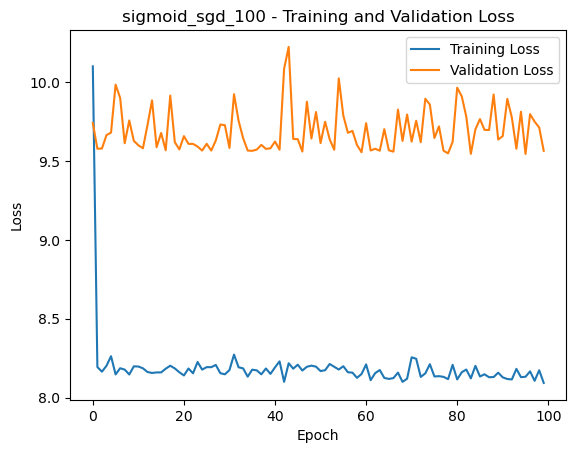

/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 13.5397 - val_loss: 9.6760
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 8.5345 - val_loss: 9.8152
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.8137 - val_loss: 9.9666
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5724 - val_loss: 9.7720
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7561 - val_loss: 9.7300
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.3089 - val_loss: 9.8323
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2537 - val_loss: 10.0079
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4795 - val_loss: 9.6128
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.4184 - val_loss: 9.5918
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9921 - val_loss: 9.7490
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 7.5578 - val_loss: 9.7121
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.0293 - val

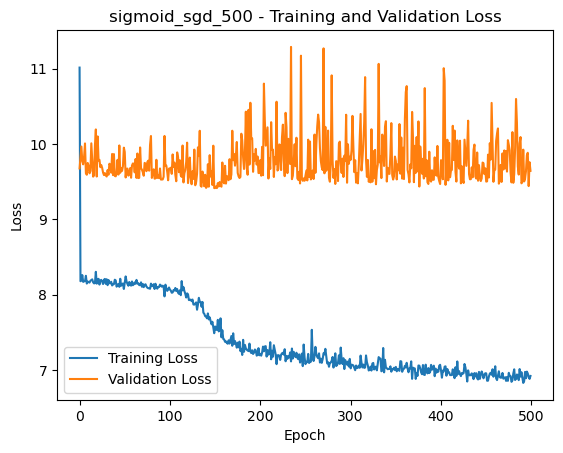

Epoch 1/100


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 23.1116 - val_loss: 17.7467
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 14.2093 - val_loss: 14.1868
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 11.7125 - val_loss: 12.4697
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 10.3937 - val_loss: 11.2454
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.2292 - val_loss: 10.7007
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.1756 - val_loss: 10.2675
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.2363 - val_loss: 9.9853
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.6590 - val_loss: 9.8432
Epoch 9/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.9542 - val_loss: 9.7789
Epoch 10/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.6185 - val_loss: 9.7271
Epoch 11/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.5580 - val_loss: 9.7436
Epoch 12/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.83

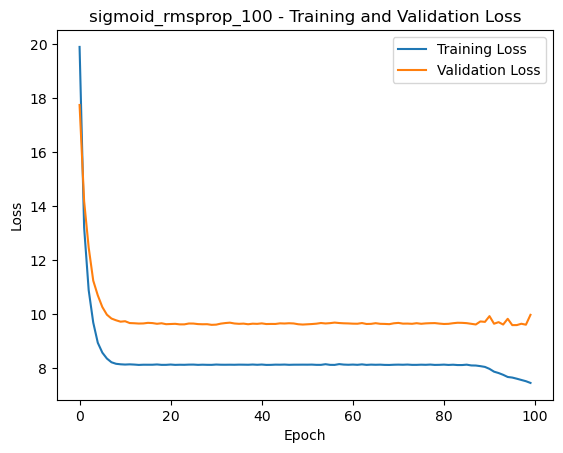

Epoch 1/500


/home/jpoulet/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 22.1753 - val_loss: 17.6308
Epoch 2/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 14.1035 - val_loss: 13.6802
Epoch 3/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 10.3791 - val_loss: 11.8856
Epoch 4/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.8445 - val_loss: 10.8000
Epoch 5/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.8297 - val_loss: 10.2635
Epoch 6/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.9937 - val_loss: 9.9805
Epoch 7/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.5442 - val_loss: 9.8242
Epoch 8/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.5142 - val_loss: 9.6886
Epoch 9/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0601 - val_loss: 9.6990
Epoch 10/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.8268 - val_loss: 9.7184
Epoch 11/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 7.7274 - val_loss: 9.6739
Epoch 12/500
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 8.0147

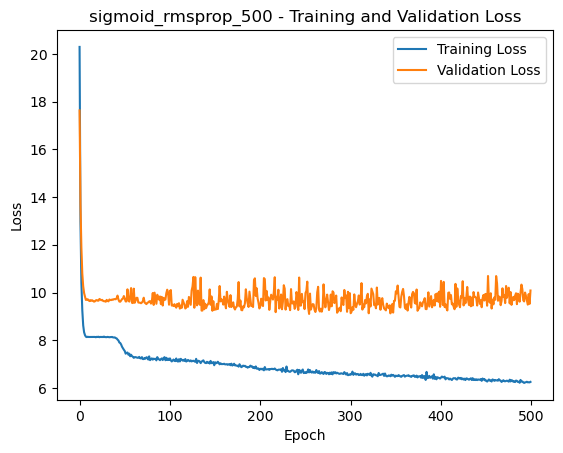

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split  # <-- Add this import
from tensorflow.keras.models import Sequential  # <-- Add this import
from tensorflow.keras.layers import Dense  # <-- Add this import

# Assuming you have run the data preparation code and have `data_cleaned`
# Use the cleaned DataFrame for splitting so the model doesn't get NaNs/infs
train_df, temp_df = train_test_split(data_cleaned, test_size=0.3, random_state=42) # 70% train, 30% temp
val_df, test_df = train_test_split(temp_df, test_size=(1/3), random_state=42) # ~10% test, ~20% validation
 # Define features (X) and target (y)

x_train = train_df[feature_cols]
y_train = train_df[target_col]
x_val = val_df[feature_cols]
y_val = val_df[target_col]
x_test = test_df[feature_cols]
y_test = test_df[target_col]

# Quick sanity checks: ensure there are no NaNs or infs in inputs/targets
def has_invalid(x):
    return np.isnan(x).any() or np.isinf(x).any()

for name, arr in [('x_train', x_train.values), ('y_train', y_train.values), ('x_val', x_val.values), ('y_val', y_val.values), ('x_test', x_test.values), ('y_test', y_test.values)]:
    if has_invalid(arr):
        raise ValueError(f"Invalid values found in {name} (NaN or Inf). Check data_cleaned and preprocessing.")




# activation_functions = ['relu', 'elu', 'selu', 'tanh', 'sigmoid']
activation_functions = ['tanh', 'sigmoid']
# activation_functions = ['tanh']
optimizers = ['adam', 'sgd', 'rmsprop']
# optimizers = ['rmsprop']
# epochs = [15, 50, 100]
epochs = [100, 500]
models = {}
for activation in activation_functions:
    for optimizer in optimizers:
        for epoch in epochs:
            model_name = f"{activation}_{optimizer}_{epoch}"
            model = Sequential([
                Dense(256, activation=activation, input_shape=(x_train.shape[1],)),  # Input layer
                Dense(128, activation=activation),  # Hidden layer
                Dense(64, activation=activation),  # Hidden layer
                Dense(32, activation=activation),  # Hidden layer
                Dense(1)  # Output layer (regression)
            ])
            model.compile(optimizer=optimizer, loss='mean_squared_error')
            history = model.fit(
                x_train, y_train,
                epochs=epoch,
                validation_data=(x_val, y_val),
                verbose=1
            )
            mse = model.evaluate(x_test, y_test, verbose=0)
            print(f'{model_name}=>Activation: {activation}, Optimizer: {optimizer}, Epochs: {epoch}, Test MSE: {mse}')
            # Store the model and its performance
            # You can use a dictionary or a list to store the models and their performance
            # For example:
            # models[activation + '_' + optimizer + '_' + str(epoch)] = (model, mse)
            models[model_name] = (model, mse)

            # 6. Visualize Training History
            import matplotlib.pyplot as plt
            plt.plot(history.history['loss'], label='Training Loss')
            plt.plot(history.history['val_loss'], label='Validation Loss')
            plt.xlabel('Epoch')
            plt.ylabel('Loss')
            plt.title(f"{model_name} - Training and Validation Loss")
            plt.legend()
            plt.show()

In [37]:
import numpy as np

if not models:
    print('No models found in `models`. Did the training cell run?')
else:
    def _safe_mse(item):
        """Return a numeric MSE for sorting or +inf when unavailable/NaN."""
        v = item[1]
        try:
            # expect v like (model, mse) or (model, mse, history)
            m = v[1]
            m = float(m)
        except Exception:
            m = float('nan')
        return m if not np.isnan(m) else float('inf')

    sorted_models = sorted(models.items(), key=_safe_mse)
    print("Models sorted by Test MSE (lowest to highest):")
    for name, val in sorted_models:
        try:
            mse_val = val[1]
            mse_str = f"{float(mse_val):.6g}"
        except Exception:
            mse_str = 'N/A'
        print(f"{name}: Test MSE = {mse_str}")

Models sorted by Test MSE (lowest to highest):
sigmoid_rmsprop_500: Test MSE = 6.49795
tanh_sgd_100: Test MSE = 6.53098
sigmoid_adam_500: Test MSE = 6.53541
sigmoid_sgd_500: Test MSE = 6.63524
tanh_adam_100: Test MSE = 6.66186
tanh_rmsprop_100: Test MSE = 6.7682
tanh_sgd_500: Test MSE = 7.15148
sigmoid_rmsprop_100: Test MSE = 7.2636
sigmoid_adam_100: Test MSE = 7.29661
sigmoid_sgd_100: Test MSE = 7.70554
tanh_rmsprop_500: Test MSE = 8.92502
tanh_adam_500: Test MSE = 9.31966


Model: tanh_adam_100, Test MSE: 6.661855697631836
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


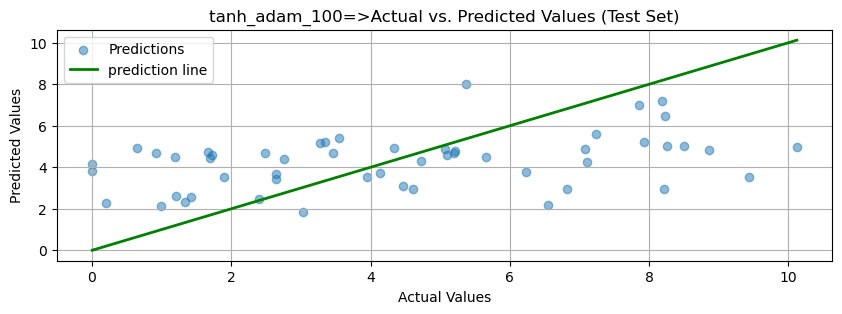

Model: tanh_adam_500, Test MSE: 9.319657325744629
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


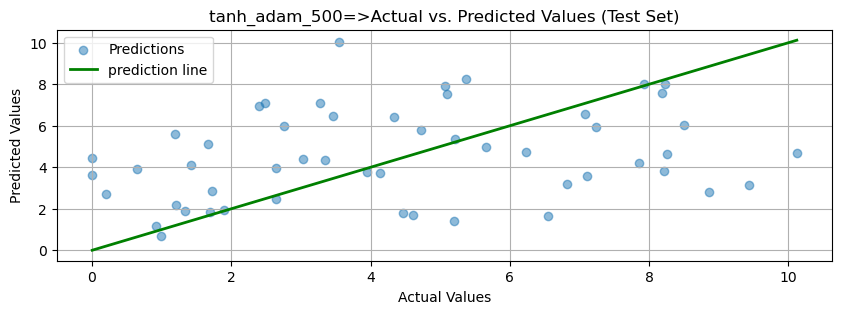

Model: tanh_sgd_100, Test MSE: 6.530977725982666
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


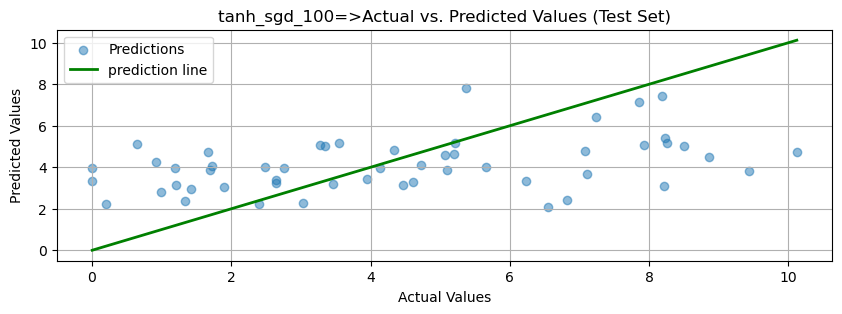

Model: tanh_sgd_500, Test MSE: 7.151482105255127
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


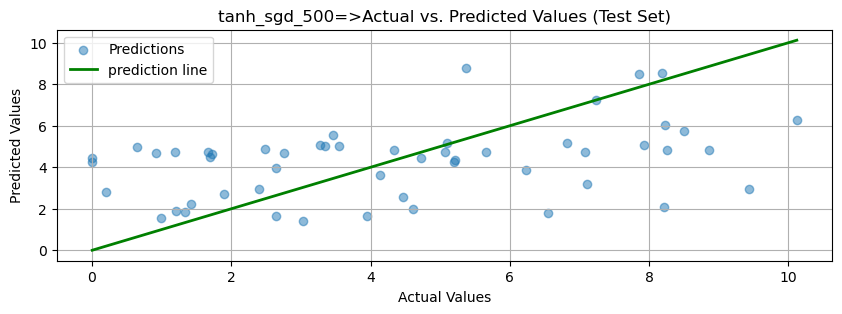

Model: tanh_rmsprop_100, Test MSE: 6.7682037353515625
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


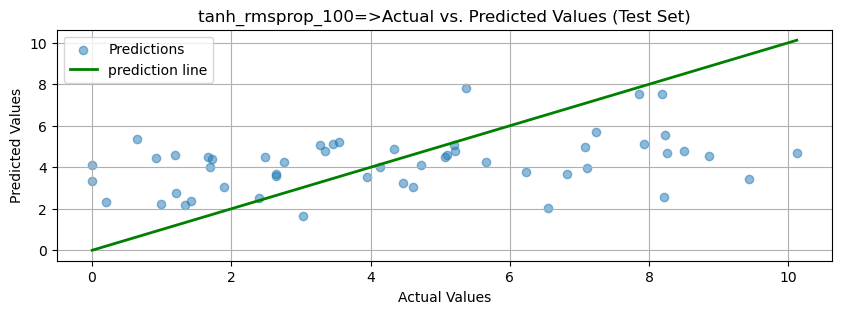

Model: tanh_rmsprop_500, Test MSE: 8.925016403198242
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


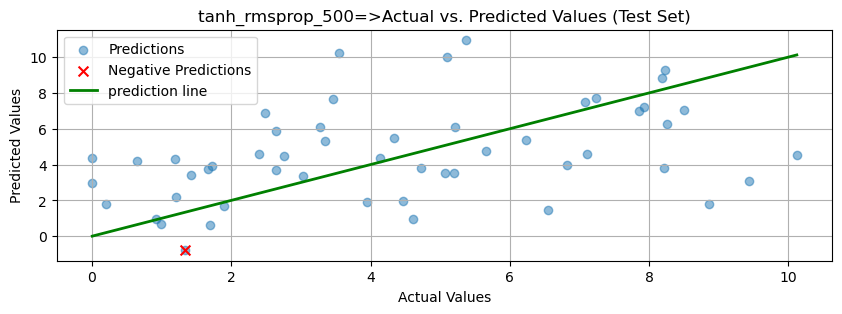

Model: sigmoid_adam_100, Test MSE: 7.296610355377197
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


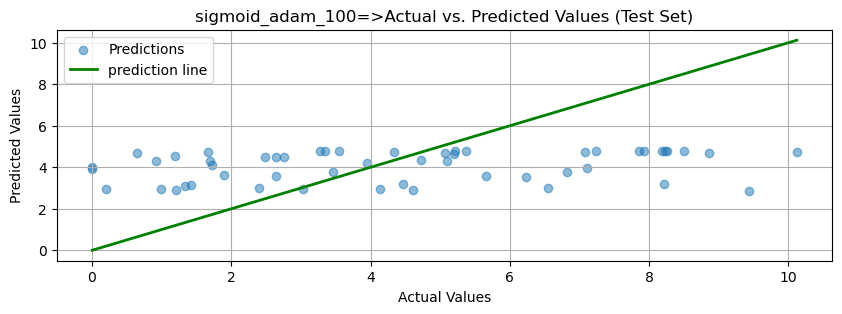

Model: sigmoid_adam_500, Test MSE: 6.5354084968566895
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


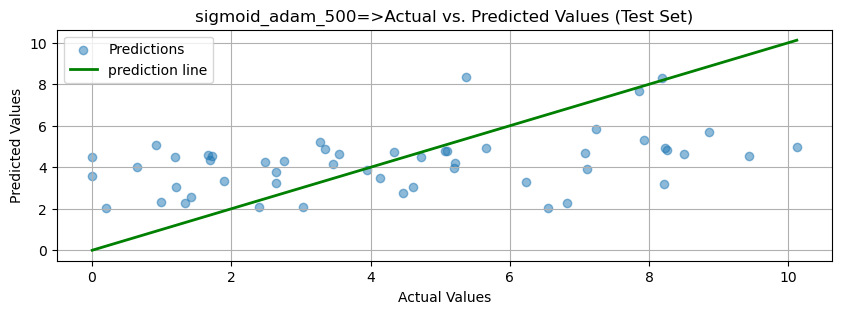

Model: sigmoid_sgd_100, Test MSE: 7.705539226531982
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


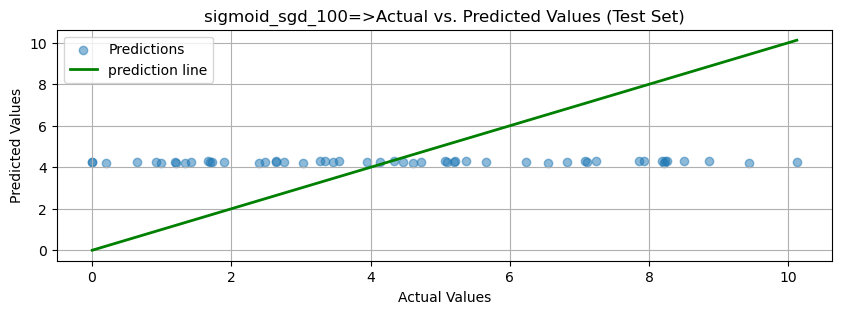

Model: sigmoid_sgd_500, Test MSE: 6.63524055480957
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


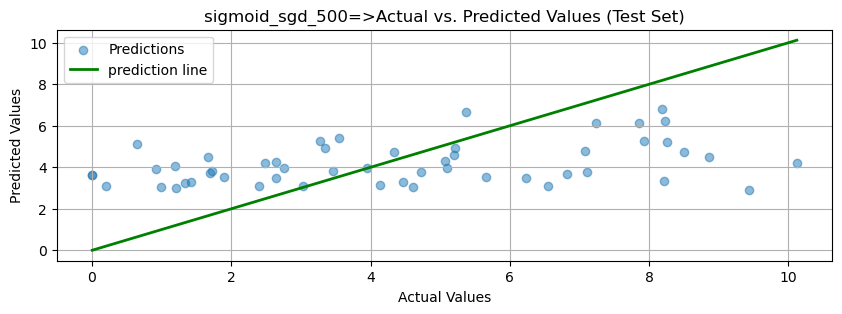

Model: sigmoid_rmsprop_100, Test MSE: 7.263598442077637
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


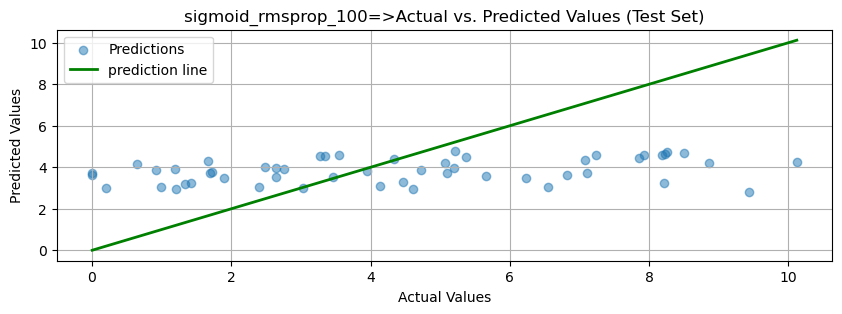

Model: sigmoid_rmsprop_500, Test MSE: 6.4979472160339355
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


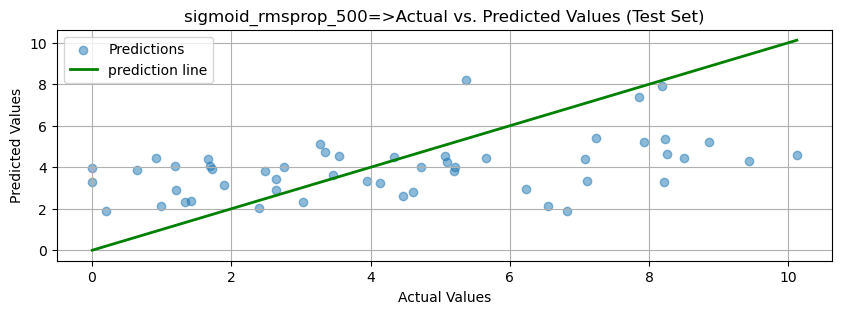

In [38]:
import matplotlib.pyplot as plt
import numpy as np

for model_name, (model, mse) in models.items():
    print(f"Model: {model_name}, Test MSE: {mse}")
    # Assuming you have already trained your model and have x_test
    # Now, let's make predictions on the test set
    if 'model' in locals() and 'x_test' in locals():
        y_pred_test = model.predict(x_test).ravel()  # Flatten to 1D

        # If y_test exists, we can compare predictions to actual values
        if 'y_test' in locals():
            # --- Test Set Visualization ---
            plt.figure(figsize=(10, 3))
            plt.scatter(y_test, y_pred_test, alpha=0.5, label='Predictions')

            # --- Highlight Negative Predictions ---
            negative_predictions_mask = y_pred_test < 0
            if np.any(negative_predictions_mask):
                plt.scatter(
                    y_test[negative_predictions_mask],
                    y_pred_test[negative_predictions_mask],
                    color='red',
                    label='Negative Predictions',
                    s=50,
                    marker='x'
                )
                print("Warning: The model predicted negative values. These might be physically unrealistic depending on what you are predicting.")

            # --- Plot the ideal prediction line ---
            min_val = min(np.min(y_test), np.min(y_test))
            max_val = max(np.max(y_test), np.max(y_test))
            p_min_val = min(np.min(y_pred_test), np.min(y_pred_test))
            p_max_val = max(np.max(y_pred_test), np.max(y_pred_test))
            plt.plot([min_val, max_val], [min_val, max_val], 'g-', lw=2, label='prediction line')

            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title(f'{model_name}=>Actual vs. Predicted Values (Test Set)')
            plt.grid(True)
            plt.legend()
            plt.show()
    else:
        print("Please ensure that the model has been trained ('model' is defined) and you have test data ('x_test' is defined).")